# Exploratory Data Analysis

## 1. EDA Objectives, Dataset & Target Definitions

This notebook establishes the foundation for later exploratory analysis of Olist delivery performance. It defines the business questions, source roles, analytical grain, identifiers, target cohorts, and purchase-time leakage boundary without building the combined analytical dataset. All calculations are read-only and leave the source CSV files unchanged.

### 1.1 Business and ML Objectives

The project has two supervised objectives at the moment an order is placed (`order_purchase_timestamp`): estimate whether an order will arrive late (`is_late`) and estimate its actual elapsed delivery duration (`delivery_days`). This EDA foundation will support later investigation of the following questions; these are **investigation areas, not proven correlations or finalized predictive features**.

| Area | Investigation |
|---|---|
| Delivery performance | Frequency of late deliveries |
| Delivery duration | Distribution of actual delivery times |
| Geography | Customer and seller location relationships |
| Order characteristics | Item count, price, freight, and product weight |
| Temporal patterns | Purchase month, weekday, and relevant timing |
| Customer behavior | Repeat-customer historical delivery patterns |
| Data reliability | Missing outcomes, invalid timestamps, and analysis limitations |

This task defines cohorts and checks only. It intentionally creates no charts, feature matrix, full order-level join, or model.

### 1.2 Dataset Loading

The loader follows the existing project convention: it discovers the repository root from the current working directory, reads from `data/raw/`, handles the translation file's possible UTF-8 BOM, and reports all missing inputs before reading any source. Original column names are preserved. Only the three timestamps required for target construction are parsed, using the explicit source format `%Y-%m-%d %H:%M:%S`, and failed non-null parses remain visible in `timestamp_parse_summary` rather than being silently accepted. Source timestamps contain no timezone offset, so they remain consistently timezone-naive.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", "{:.4f}".format)


def find_project_root(start: Path) -> Path:
    """Locate the repository by its immutable raw-data directory.

    Searching the current directory and its parents lets the notebook run
    from either the repository root or `notebooks/`. A clear exception is
    raised instead of falling back to a machine-specific location.
    """
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "data" / "raw").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project data/raw directory.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

DATASET_FILES = {
    "Orders": "olist_orders_dataset.csv",
    "Customers": "olist_customers_dataset.csv",
    "Order Items": "olist_order_items_dataset.csv",
    "Products": "olist_products_dataset.csv",
    "Sellers": "olist_sellers_dataset.csv",
    "Payments": "olist_order_payments_dataset.csv",
    "Reviews": "olist_order_reviews_dataset.csv",
    "Geolocation": "olist_geolocation_dataset.csv",
    "Category Translation": "product_category_name_translation.csv",
}

missing_files = [
    file_name
    for file_name in DATASET_FILES.values()
    if not (RAW_DATA_DIR / file_name).is_file()
]
if missing_files:
    raise FileNotFoundError(
        f"Missing required source CSV files in {RAW_DATA_DIR}: {missing_files}"
    )


def load_source_csv(file_name: str) -> pd.DataFrame:
    """Load one immutable Olist CSV while preserving its source schema.

    UTF-8 with BOM support is used because the category translation header
    contains a BOM in this snapshot. The function performs no cleaning.
    """
    return pd.read_csv(RAW_DATA_DIR / file_name, encoding="utf-8-sig")


datasets = {
    dataset_name: load_source_csv(file_name)
    for dataset_name, file_name in DATASET_FILES.items()
}

orders = datasets["Orders"]
customers = datasets["Customers"]
order_items = datasets["Order Items"]
products = datasets["Products"]
sellers = datasets["Sellers"]
payments = datasets["Payments"]
reviews = datasets["Reviews"]
geolocation = datasets["Geolocation"]
category_translation = datasets["Category Translation"]

TARGET_TIMESTAMP_COLUMNS = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

missing_target_columns = [
    column for column in TARGET_TIMESTAMP_COLUMNS if column not in orders.columns
]
if missing_target_columns:
    raise KeyError(f"Orders is missing target columns: {missing_target_columns}")

# An explicit format prevents pandas from silently inferring a different
# layout (for example day-first dates) if the source format ever changes.
SOURCE_TIMESTAMP_FORMAT = "%Y-%m-%d %H:%M:%S"

timestamp_parse_rows = []
for column in TARGET_TIMESTAMP_COLUMNS:
    original_non_null = orders[column].notna()
    parsed = pd.to_datetime(
        orders[column], format=SOURCE_TIMESTAMP_FORMAT, errors="coerce"
    )
    failed_non_null = original_non_null & parsed.isna()
    timestamp_parse_rows.append(
        {
            "timestamp": column,
            "source_non_null": int(original_non_null.sum()),
            "parsed_non_null": int(parsed.notna().sum()),
            "failed_non_null_parses": int(failed_non_null.sum()),
        }
    )
    orders[column] = parsed

timestamp_parse_summary = pd.DataFrame(timestamp_parse_rows)
display(timestamp_parse_summary)

if timestamp_parse_summary["failed_non_null_parses"].sum():
    raise ValueError("One or more populated target timestamps could not be parsed.")

,timestamp,source_non_null,parsed_non_null,failed_non_null_parses
0,order_purchase_timestamp,99441,99441,0
1,order_delivered_customer_date,96476,96476,0
2,order_estimated_delivery_date,99441,99441,0


In [2]:
DATASET_GRAINS = {
    "Orders": "One row per order_id",
    "Customers": "One row per customer_id (order-specific customer record)",
    "Order Items": "One row per (order_id, order_item_id)",
    "Products": "One row per product_id",
    "Sellers": "One row per seller_id",
    "Payments": "One row per (order_id, payment_sequential)",
    "Reviews": "One review record per row; order_id can repeat",
    "Geolocation": "Raw geographic observation; ZIP prefix can repeat",
    "Category Translation": "One row per Portuguese product category",
}

DATASET_ROLES = {
    "Orders": "Order-level foundation and target timestamps",
    "Customers": "Customer identity and location context",
    "Order Items": "Order composition, product, seller, price, and freight",
    "Products": "Product category and physical attributes",
    "Sellers": "Seller identity and location context",
    "Payments": "Payment records; availability must be verified",
    "Reviews": "Retrospective post-purchase analysis only",
    "Geolocation": "Static ZIP-prefix geography after later deduplication",
    "Category Translation": "Static Portuguese-to-English category lookup",
}

dataset_inventory = pd.DataFrame(
    [
        {
            "dataset": dataset_name,
            "rows": len(dataframe),
            "columns": dataframe.shape[1],
            "analytical_grain": DATASET_GRAINS[dataset_name],
            "intended_eda_role": DATASET_ROLES[dataset_name],
        }
        for dataset_name, dataframe in datasets.items()
    ]
)
dataset_inventory

,dataset,rows,columns,analytical_grain,intended_eda_role
0,Orders,99441,8,One row per order_id,Order-level foundation and target timestamps
1,Customers,99441,5,One row per customer_id (order-specific customer record),Customer identity and location context
2,Order Items,112650,7,"One row per (order_id, order_item_id)","Order composition, product, seller, price, and freight"
3,Products,32951,9,One row per product_id,Product category and physical attributes
4,Sellers,3095,4,One row per seller_id,Seller identity and location context
5,Payments,103886,5,"One row per (order_id, payment_sequential)",Payment records; availability must be verified
6,Reviews,99224,7,One review record per row; order_id can repeat,Retrospective post-purchase analysis only
7,Geolocation,1000163,5,Raw geographic observation; ZIP prefix can repeat,Static ZIP-prefix geography after later deduplication
8,Category Translation,71,2,One row per Portuguese product category,Static Portuguese-to-English category lookup


### 1.3 Dataset Roles and Analytical Grain

The primary EDA grain is **one row per order, uniquely identified by `order_id`**, with Orders as the analytical foundation. Source relationships must be respected before later construction of an order-level view.

| Relationship | Cardinality toward the referenced table | Later join control |
|---|---|---|
| Orders → Customers on `customer_id` | Many-to-one conceptually; one-to-one in this snapshot's order-specific key | Validate customer uniqueness and retain unmatched evidence |
| Orders → Order Items on `order_id` | One-to-many | Aggregate items independently to order grain |
| Orders → Payments on `order_id` | One-to-many | Aggregate payments independently to order grain |
| Orders → Reviews on `order_id` | One-to-many for some orders | Controlled deduplication/aggregation for retrospective analysis only |
| Order Items → Products on `product_id` | Many-to-one | Enrich item rows before later order aggregation |
| Order Items → Sellers on `seller_id` | Many-to-one | Preserve multi-seller orders; aggregate after enrichment |
| Customer/Seller ZIP prefix → Geolocation | Many-to-many if raw | Build a documented unique ZIP lookup first |
| Products → Category Translation | Many-to-one | Left join later and preserve untranslated source categories |

Directly joining raw one-to-many sources would multiply order rows and corrupt counts, sums, and target weights. No such join is performed here.

### 1.4 Identifier Retention Policy

| Identifier | Analytical role | Model-input policy |
|---|---|---|
| `order_id` | Primary order-level key, lineage, and reconciliation | Retain for tracing; exclude as a raw baseline feature |
| `customer_id` | Required Orders-to-Customers join key | Retain for joins; exclude raw identity |
| `customer_unique_id` | Cross-order identity for the underlying customer | Retain for later point-in-time history; exclude raw identity |
| `product_id` | Product-level joining and tracing in detailed item views | Preserve before aggregation; exclude raw identity |
| `seller_id` | Seller-level joining and tracing in detailed item views | Preserve before aggregation; exclude raw identity |

Identifiers are useful analytical controls even when they are unsuitable raw predictive features. Multi-item orders may contain several products and sellers, so no arbitrary product or seller is selected as representative. Customer-history engineering is deferred.

### 1.5 Classification Target Definition

For an eligible delivered order, `is_late = 1` when `order_delivered_customer_date > order_estimated_delivery_date`; otherwise it is `0`. Equality is on time. The comparison is strict and timestamp-based, and both timestamps share the source's timezone-naive convention.

**Estimated-date granularity.** Every `order_estimated_delivery_date` value is stored at `00:00:00`, so the estimate behaves like a calendar date. Under the strict rule, an order delivered later on the estimated calendar day is labeled late. The count of these same-day late orders is computed below and reported in the key findings; the strict rule is retained because changing it is a governance decision that would require updating `PROJECT_PROBLEM.md` and a label-sensitivity comparison.

**Eligibility (provisional design decision, pending owner approval).** `PROJECT_PROBLEM.md` defines eligibility through valid actual and estimated delivery timestamps and describes the target for an *eligible delivered order*; it also lists the exact label-eligible cohort as an assumption to validate, and `DATA_DICTIONARY.md` records the status requirement as an open decision. This notebook provisionally requires:

1. `order_status == "delivered"`;
2. parseable actual and estimated delivery timestamps;
3. actual delivery not before purchase; and
4. estimated delivery not before purchase.

Rules 3 and 4 guard against chronologically impossible records rather than silently labeling them. The timestamp-complete rows excluded only by the status rule are listed by status below for owner review. Ineligible rows keep a nullable target rather than being mislabeled on time.

In [3]:
delivered_status = orders["order_status"].eq("delivered")
classification_timestamps_valid = orders[
    ["order_delivered_customer_date", "order_estimated_delivery_date"]
].notna().all(axis=1)
actual_not_before_purchase = (
    orders["order_delivered_customer_date"]
    >= orders["order_purchase_timestamp"]
)
estimate_not_before_purchase = (
    orders["order_estimated_delivery_date"]
    >= orders["order_purchase_timestamp"]
)
classification_eligible = (
    delivered_status
    & classification_timestamps_valid
    & actual_not_before_purchase.fillna(False)
    & estimate_not_before_purchase.fillna(False)
)

# Nullable integers keep excluded orders visibly unlabeled rather than
# allowing missing outcomes to become a misleading on-time class.
orders["is_late"] = pd.Series(pd.NA, index=orders.index, dtype="Int8")
orders.loc[classification_eligible, "is_late"] = (
    orders.loc[classification_eligible, "order_delivered_customer_date"]
    > orders.loc[classification_eligible, "order_estimated_delivery_date"]
).astype("Int8")

# The estimate is stored at midnight, so a delivery later on the same calendar
# day is late under the strict rule; this count quantifies that convention.
same_day_late = (
    classification_eligible
    & orders["is_late"].eq(1).fillna(False)
    & orders["order_delivered_customer_date"].dt.normalize().eq(
        orders["order_estimated_delivery_date"]
    )
)

# Rows that satisfy the timestamp rules but are excluded only by the
# provisional delivered-status rule; shown by status for governance review.
status_only_exclusions = ~delivered_status & classification_timestamps_valid

classification_summary = pd.DataFrame(
    {
        "metric": [
            "Total orders",
            "Classification-eligible orders",
            "Classification-ineligible orders",
            "Eligible late orders",
            "Eligible on-time orders",
            "Eligible late orders delivered on the estimated calendar day",
            "Timestamp-complete non-delivered orders (governance diagnostic)",
        ],
        "count": [
            len(orders),
            int(classification_eligible.sum()),
            int((~classification_eligible).sum()),
            int(orders.loc[classification_eligible, "is_late"].eq(1).sum()),
            int(orders.loc[classification_eligible, "is_late"].eq(0).sum()),
            int(same_day_late.sum()),
            int(status_only_exclusions.sum()),
        ],
    }
)
display(classification_summary)

status_only_exclusion_breakdown = (
    orders.loc[status_only_exclusions, "order_status"]
    .value_counts()
    .rename_axis("order_status")
    .reset_index(name="timestamp_complete_rows")
)
status_only_exclusion_breakdown

,metric,count
0,Total orders,99441
1,Classification-eligible orders,96470
2,Classification-ineligible orders,2971
3,Eligible late orders,7826
4,Eligible on-time orders,88644
5,Eligible late orders delivered on the estimated calendar day,1292
6,Timestamp-complete non-delivered orders (governance diagnostic),6


,order_status,timestamp_complete_rows
0,canceled,6


### 1.6 Regression Target Definition

For an eligible delivered order, `delivery_days` is actual elapsed time from purchase to customer delivery: `(order_delivered_customer_date - order_purchase_timestamp).total_seconds() / 86,400`. Fractional days are preserved. Estimated duration is not substituted for the actual outcome.

Regression eligibility is evaluated independently from classification under the same provisional status decision described in 1.5: status is `delivered`, purchase and actual-delivery timestamps parse, and elapsed duration is nonnegative. A negative duration remains invalid and unlabeled; it is never clipped or repaired silently.

In [4]:
delivery_duration_days = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / 86_400
regression_timestamps_valid = orders[
    ["order_purchase_timestamp", "order_delivered_customer_date"]
].notna().all(axis=1)
negative_duration = regression_timestamps_valid & delivery_duration_days.lt(0)
regression_eligible = (
    delivered_status & regression_timestamps_valid & ~negative_duration
)

orders["delivery_days"] = pd.Series(
    pd.NA, index=orders.index, dtype="Float64"
)
orders.loc[regression_eligible, "delivery_days"] = delivery_duration_days.loc[
    regression_eligible
]

regression_summary = pd.DataFrame(
    {
        "metric": [
            "Total orders",
            "Regression-eligible orders",
            "Regression-ineligible orders",
            "Invalid or negative durations",
            "Timestamp-complete non-delivered orders (governance diagnostic)",
        ],
        "count": [
            len(orders),
            int(regression_eligible.sum()),
            int((~regression_eligible).sum()),
            int(negative_duration.sum()),
            int((~delivered_status & regression_timestamps_valid).sum()),
        ],
    }
)
regression_summary

,metric,count
0,Total orders,99441
1,Regression-eligible orders,96470
2,Regression-ineligible orders,2971
3,Invalid or negative durations,0
4,Timestamp-complete non-delivered orders (governance diagnostic),6


### 1.7 Prediction-Time Availability and Data Leakage

Every future feature must be reproducible at the purchase-time boundary. Target construction may use later outcomes, but predictive inputs may not.

| Availability group | Examples | Policy |
|---|---|---|
| Identifiers | `order_id`, `customer_id`, `customer_unique_id` | Retain for joins, tracing, and analysis; exclude raw identifiers from baseline features |
| Candidate purchase-time information | Customer geography, product characteristics, item count, item price, freight, purchase timestamp components | Candidate only; later work must validate aggregation and serving parity |
| Requires availability verification | Payment attributes, estimated delivery date, shipping limit date, fields finalized or updated after placement | Exclude until the operational contract proves purchase-time availability |
| Post-purchase information | Approval/carrier/actual-delivery timestamps, status outcomes, reviews, fulfillment outcomes | Prohibited predictive features |

This notebook deliberately places the estimated delivery date in the verification tier, which is more conservative than `PROJECT_PROBLEM.md` section 4.3, where the delivery promise is listed as a candidate. Phase 3 must confirm when the estimate is created and whether it is ever revised before the date is approved as an input.

Actual delivery timestamps, `is_late`, and `delivery_days` are retained here only for retrospective EDA and label construction. They must never enter purchase-time feature matrices. Historical customer, seller, or route outcomes would also require strictly prior, already-observed events; no such features are built in this task.

### 1.8 Target Eligibility and Foundation Checks

The following checks validate the order spine, customer link, native one-to-many behavior, and target invariants without constructing the combined dataset. Assertions fail with diagnostic context when an invariant is broken.

In [5]:
required_order_columns = {
    "order_id",
    "customer_id",
    "order_status",
    *TARGET_TIMESTAMP_COLUMNS,
}
required_customer_columns = {"customer_id", "customer_unique_id"}
missing_order_columns = sorted(required_order_columns - set(orders.columns))
missing_customer_columns = sorted(required_customer_columns - set(customers.columns))
assert not missing_order_columns, f"Missing required Orders columns: {missing_order_columns}"
assert not missing_customer_columns, (
    f"Missing required Customers columns: {missing_customer_columns}"
)

unmatched_customer_mask = ~orders["customer_id"].isin(customers["customer_id"])
foundation_checks = pd.DataFrame(
    {
        "check": [
            "Total orders",
            "Null order_id values",
            "Duplicate order_id occurrences",
            "Unique customer_id in Customers",
            "Orders without a matching customer_id",
            "customer_unique_id available",
        ],
        "result": [
            len(orders),
            int(orders["order_id"].isna().sum()),
            int(orders["order_id"].duplicated().sum()),
            bool(customers["customer_id"].is_unique),
            int(unmatched_customer_mask.sum()),
            "customer_unique_id" in customers.columns,
        ],
    }
)
display(foundation_checks)

assert orders["order_id"].notna().all(), "Orders contains null order_id values."
assert orders["order_id"].is_unique, "Orders does not have one row per order_id."
assert customers["customer_id"].is_unique, (
    "Customers.customer_id must be unique for a safe many-to-one join."
)
assert not unmatched_customer_mask.any(), (
    f"{int(unmatched_customer_mask.sum())} orders lack a matching customer_id."
)

,check,result
0,Total orders,99441
1,Null order_id values,0
2,Duplicate order_id occurrences,0
3,Unique customer_id in Customers,True
4,Orders without a matching customer_id,0
5,customer_unique_id available,True


In [6]:
relationship_checks = pd.DataFrame(
    [
        {
            "dataset": "Order Items",
            "rows": len(order_items),
            "distinct_orders": order_items["order_id"].nunique(),
            "orders_with_multiple_rows": int(
                order_items["order_id"].value_counts().gt(1).sum()
            ),
            "requires_order_level_control": True,
        },
        {
            "dataset": "Payments",
            "rows": len(payments),
            "distinct_orders": payments["order_id"].nunique(),
            "orders_with_multiple_rows": int(
                payments["order_id"].value_counts().gt(1).sum()
            ),
            "requires_order_level_control": True,
        },
        {
            "dataset": "Reviews",
            "rows": len(reviews),
            "distinct_orders": reviews["order_id"].nunique(),
            "orders_with_multiple_rows": int(
                reviews["order_id"].value_counts().gt(1).sum()
            ),
            "requires_order_level_control": True,
        },
    ]
)
display(relationship_checks)

# Reconciliation checks protect against accidentally assigning labels outside
# the independently defined cohorts or changing their intended domains.
# Each check is evaluated once, displayed, and then enforced. Eligible labels
# are tested for completeness explicitly because pandas skips missing values
# in reductions such as `.ge(0).all()`, which would let an all-missing target
# pass a range check.
eligible_is_late = orders.loc[classification_eligible, "is_late"]
eligible_delivery_days = orders.loc[regression_eligible, "delivery_days"]
target_check_results = {
    "Classification counts reconcile": (
        int(classification_eligible.sum()) + int((~classification_eligible).sum())
        == len(orders)
    ),
    "Eligible classification labels are populated": bool(eligible_is_late.notna().all()),
    "Eligible classification labels are binary": bool(eligible_is_late.isin([0, 1]).all()),
    "Ineligible classification rows are nullable": bool(
        orders.loc[~classification_eligible, "is_late"].isna().all()
    ),
    "Regression counts reconcile": (
        int(regression_eligible.sum()) + int((~regression_eligible).sum())
        == len(orders)
    ),
    "Eligible regression labels are populated": bool(eligible_delivery_days.notna().all()),
    # Missing values fail here too, instead of being skipped or raising an
    # ambiguous NA error, so the assertion below reports a readable message.
    "Eligible regression labels are nonnegative": bool(
        eligible_delivery_days.ge(0).fillna(False).all()
    ),
    "Ineligible regression rows are nullable": bool(
        orders.loc[~regression_eligible, "delivery_days"].isna().all()
    ),
}
target_checks = pd.DataFrame(
    {"check": list(target_check_results), "passed": list(target_check_results.values())}
)
display(target_checks)

failed_target_checks = [name for name, passed in target_check_results.items() if not passed]
assert not failed_target_checks, f"Target invariant checks failed: {failed_target_checks}"

,dataset,rows,distinct_orders,orders_with_multiple_rows,requires_order_level_control
0,Order Items,112650,98666,9803,True
1,Payments,103886,99440,2961,True
2,Reviews,99224,98673,547,True


,check,passed
0,Classification counts reconcile,True
1,Eligible classification labels are populated,True
2,Eligible classification labels are binary,True
3,Ineligible classification rows are nullable,True
4,Regression counts reconcile,True
5,Eligible regression labels are populated,True
6,Eligible regression labels are nonnegative,True
7,Ineligible regression rows are nullable,True


### 1.9 Key Findings and Assumptions

The next cell generates the summary from executed checks rather than hardcoding observed counts. Important exclusions are missing or invalid target timestamps, non-delivered statuses under the provisional delivered-status decision, and chronologically impossible target timestamps.

Open items for owner review:

- **Status cohort:** the timestamp-complete non-delivered records are excluded provisionally. The decision should be recorded in `PROJECT_PROBLEM.md` before it is treated as authoritative.
- **Estimate granularity:** same-day late deliveries depend on the strict midnight-estimate convention.
- **Serving availability:** estimated-delivery and payment availability at the purchase-time boundary remain to be verified.

Other lifecycle anomalies, such as delivery recorded before carrier handoff or approval, do not enter either target formula. They are investigated in `02_data_quality.ipynb` and are not used as additional exclusions here.

In [7]:
key_findings = pd.DataFrame(
    {
        "finding": [
            "Actual order count",
            "Primary-key validation",
            "Customer relationship validation",
            "Classification eligibility",
            "Regression eligibility",
            "Classification class counts",
            "Invalid negative durations",
            "Same-day late deliveries (midnight estimate)",
            "Unresolved status-cohort records",
        ],
        "observed_result": [
            f"{len(orders):,}",
            f"PASS: {orders['order_id'].nunique():,} unique non-null order_id values",
            f"PASS: {int(unmatched_customer_mask.sum()):,} unmatched orders; customer_id unique={customers['customer_id'].is_unique}",
            f"{int(classification_eligible.sum()):,} eligible; {int((~classification_eligible).sum()):,} excluded",
            f"{int(regression_eligible.sum()):,} eligible; {int((~regression_eligible).sum()):,} excluded",
            f"{int(orders['is_late'].eq(1).sum()):,} late; {int(orders['is_late'].eq(0).sum()):,} on time",
            f"{int(negative_duration.sum()):,}",
            f"{int(same_day_late.sum()):,} late orders delivered on the estimated calendar day",
            f"{int(status_only_exclusions.sum()):,} timestamp-complete non-delivered orders excluded pending governance ("
            + ", ".join(
                f"{status}: {count}"
                for status, count in orders.loc[status_only_exclusions, "order_status"]
                .value_counts()
                .items()
            )
            + ")",
        ],
    }
)
key_findings

,finding,observed_result
0,Actual order count,"99,441"
1,Primary-key validation,"PASS: 99,441 unique non-null order_id values"
2,Customer relationship validation,PASS: 0 unmatched orders; customer_id unique=True
3,Classification eligibility,"96,470 eligible; 2,971 excluded"
4,Regression eligibility,"96,470 eligible; 2,971 excluded"
5,Classification class counts,"7,826 late; 88,644 on time"
6,Invalid negative durations,0
7,Same-day late deliveries (midnight estimate),"1,292 late orders delivered on the estimated calendar day"
8,Unresolved status-cohort records,6 timestamp-complete non-delivered orders excluded pending governance (canceled: 6)


### 1.10 Learning Questions

These questions are intentionally unanswered.

1. Why is `order_id` the primary analytical key?
2. What is the difference between `customer_id` and `customer_unique_id`?
3. Why can multiple order-item records belong to one order?
4. What happens when we directly join a one-to-many table with the orders dataset?
5. Why can classification and regression have different eligible populations?
6. What is data leakage, and how can actual delivery information cause it?
7. Why might we retain an identifier in our analytical dataset but exclude it from model training?

## 2. Target Variable Exploration

This section explores the two Task 1.1 targets without redefining them. Every denominator uses the existing eligibility masks, and excluded orders retain nullable targets. The delivered-status cohort rule remains provisional: Task 1.1 excludes six timestamp-complete non-delivered orders pending governance approval, so all results below consistently describe that existing conservative cohort.

### 2.1 Classification — Class Distribution

The class distribution uses only populated `is_late` labels selected by `classification_eligible`. Counts are reconciled to that population before percentages or the chart are produced.

Class,Count,Percentage
On time (0),"88,644",91.89%
Late (1),"7,826",8.11%
Total,"96,470",100.00%


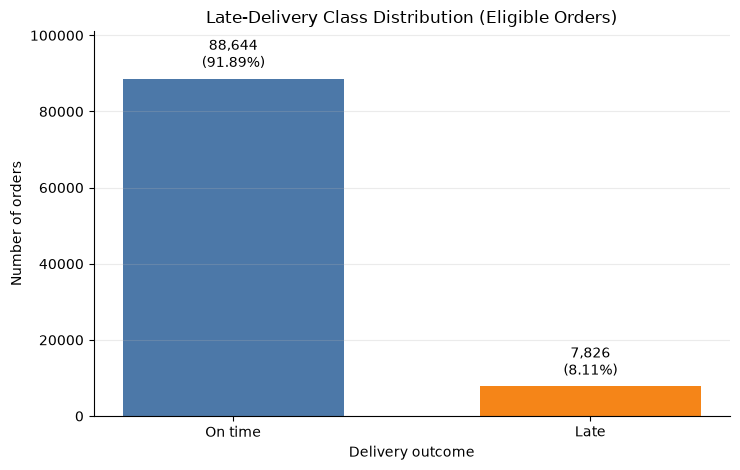

Among **96,470** eligible orders, **88,644 (91.89%)** were on time and **7,826 (8.11%)** were late. The two counts reconcile exactly to the eligible classification population.

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown

eligible_classification_target = orders.loc[classification_eligible, "is_late"].dropna()
classification_eligible_count = len(eligible_classification_target)
class_counts = eligible_classification_target.value_counts().reindex([0, 1], fill_value=0)
on_time_count = int(class_counts.loc[0])
late_count = int(class_counts.loc[1])
class_percentages = class_counts.div(classification_eligible_count).mul(100)

assert classification_eligible_count == int(classification_eligible.sum())
assert int(class_counts.sum()) == classification_eligible_count
assert np.isclose(class_percentages.sum(), 100.0)

class_distribution = pd.DataFrame(
    {
        "Class": ["On time (0)", "Late (1)", "Total"],
        "Count": [on_time_count, late_count, classification_eligible_count],
        "Percentage": [
            class_percentages.loc[0],
            class_percentages.loc[1],
            100.0,
        ],
    }
)
display(
    class_distribution.style.format(
        {"Count": "{:,}", "Percentage": "{:.2f}%"}
    ).hide(axis="index")
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
labels = ["On time", "Late"]
counts = [on_time_count, late_count]
percentages = [class_percentages.loc[0], class_percentages.loc[1]]
bars = ax.bar(labels, counts, color=["#4C78A8", "#F58518"], width=0.62)
for bar, count, percentage in zip(bars, counts, percentages):
    ax.annotate(
        f"{count:,}\n({percentage:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )
ax.set_title("Late-Delivery Class Distribution (Eligible Orders)")
ax.set_xlabel("Delivery outcome")
ax.set_ylabel("Number of orders")
ax.set_ylim(0, max(counts) * 1.14)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

display(Markdown(
    f"Among **{classification_eligible_count:,}** eligible orders, "
    f"**{on_time_count:,} ({class_percentages.loc[0]:.2f}%)** were on time and "
    f"**{late_count:,} ({class_percentages.loc[1]:.2f}%)** were late. "
    "The two counts reconcile exactly to the eligible classification population."
))

### 2.2 Classification — Class Imbalance Assessment

The majority-class-only accuracy below is a mathematical reference, not a trained classifier or an evaluation result. It shows why accuracy must be interpreted against the observed class distribution.

In [9]:
class_names = {0: "On time (0)", 1: "Late (1)"}
majority_value = int(class_counts.idxmax())
minority_value = int(class_counts.idxmin())
majority_count = int(class_counts.loc[majority_value])
minority_count = int(class_counts.loc[minority_value])
majority_minority_ratio = majority_count / minority_count
minority_percentage = minority_count / classification_eligible_count * 100
majority_baseline_accuracy = majority_count / classification_eligible_count * 100

imbalance_summary = pd.DataFrame(
    {
        "Metric": [
            "Majority class",
            "Minority class",
            "Majority-class count",
            "Minority-class count",
            "Majority/minority ratio",
            "Minority-class percentage",
            "Always-majority accuracy",
        ],
        "Value": [
            class_names[majority_value],
            class_names[minority_value],
            f"{majority_count:,}",
            f"{minority_count:,}",
            f"{majority_minority_ratio:.2f}:1",
            f"{minority_percentage:.2f}%",
            f"{majority_baseline_accuracy:.2f}%",
        ],
    }
)
display(imbalance_summary.style.hide(axis="index"))

display(Markdown(
    f"The target is imbalanced: **{class_names[minority_value]}** is the minority class "
    f"at **{minority_percentage:.2f}%**, and the majority/minority ratio is "
    f"**{majority_minority_ratio:.2f}:1**. Always predicting "
    f"{class_names[majority_value]} would achieve **{majority_baseline_accuracy:.2f}% accuracy** "
    "while detecting no minority cases. Accuracy alone can therefore conceal poor late-delivery detection. "
    "During later modeling, precision will describe how reliable late alerts are, recall how many late orders are found, "
    "F1 will balance precision and recall, and PR-AUC will assess ranking quality with emphasis on the minority class."
))

Metric,Value
Majority class,On time (0)
Minority class,Late (1)
Majority-class count,"88,644"
Minority-class count,"7,826"
Majority/minority ratio,11.33:1
Minority-class percentage,8.11%
Always-majority accuracy,91.89%


The target is imbalanced: **Late (1)** is the minority class at **8.11%**, and the majority/minority ratio is **11.33:1**. Always predicting On time (0) would achieve **91.89% accuracy** while detecting no minority cases. Accuracy alone can therefore conceal poor late-delivery detection. During later modeling, precision will describe how reliable late alerts are, recall how many late orders are found, F1 will balance precision and recall, and PR-AUC will assess ranking quality with emphasis on the minority class.

### 2.3 Regression — Descriptive Statistics

The statistics below use every populated `delivery_days` value selected by `regression_eligible`. Calculations retain full fractional-day precision; rounding is applied only to the displayed table.

In [10]:
eligible_delivery_days = orders.loc[regression_eligible, "delivery_days"].dropna().astype(float)
regression_eligible_count = len(eligible_delivery_days)
delivery_quantiles = eligible_delivery_days.quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)
delivery_mean = eligible_delivery_days.mean()
delivery_median = eligible_delivery_days.median()
delivery_std = eligible_delivery_days.std()
delivery_min = eligible_delivery_days.min()
delivery_max = eligible_delivery_days.max()
q1 = delivery_quantiles.loc[0.25]
q3 = delivery_quantiles.loc[0.75]
delivery_iqr = q3 - q1
delivery_skewness = eligible_delivery_days.skew()

assert regression_eligible_count == int(regression_eligible.sum())
assert np.isfinite(eligible_delivery_days.to_numpy()).all()
assert eligible_delivery_days.ge(0).all()
assert delivery_quantiles.is_monotonic_increasing

regression_statistics = pd.DataFrame(
    {
        "Statistic": [
            "Count", "Mean", "Median", "Minimum", "Maximum",
            "Standard deviation", "P25", "P50", "P75",
            "P90", "P95", "P99", "IQR", "Skewness",
        ],
        "Value": [
            regression_eligible_count, delivery_mean, delivery_median, delivery_min,
            delivery_max, delivery_std, delivery_quantiles.loc[0.25],
            delivery_quantiles.loc[0.50], delivery_quantiles.loc[0.75],
            delivery_quantiles.loc[0.90], delivery_quantiles.loc[0.95],
            delivery_quantiles.loc[0.99], delivery_iqr, delivery_skewness,
        ],
        "Unit": [
            "orders", "days", "days", "days", "days", "days",
            "days", "days", "days", "days", "days", "days",
            "days", "unitless",
        ],
    }
)
display(regression_statistics.style.format({"Value": "{:.2f}"}).hide(axis="index"))

display(Markdown(
    f"The mean delivery duration is **{delivery_mean:.2f} days**, compared with a median of "
    f"**{delivery_median:.2f} days**. Standard deviation (**{delivery_std:.2f} days**) measures "
    f"overall dispersion around the mean and is sensitive to extreme values; the IQR "
    f"(**{delivery_iqr:.2f} days**) describes the middle 50% from **{q1:.2f}** to **{q3:.2f} days**. "
    f"A typical middle order took about {delivery_median:.2f} days, whereas P90, P95, and P99 were "
    f"{delivery_quantiles.loc[0.90]:.2f}, {delivery_quantiles.loc[0.95]:.2f}, and "
    f"{delivery_quantiles.loc[0.99]:.2f} days, respectively."
))

Statistic,Value,Unit
Count,96470.00,orders
Mean,12.56,days
Median,10.22,days
Minimum,0.53,days
Maximum,209.63,days
Standard deviation,9.55,days
P25,6.77,days
P50,10.22,days
P75,15.72,days
P90,23.10,days


The mean delivery duration is **12.56 days**, compared with a median of **10.22 days**. Standard deviation (**9.55 days**) measures overall dispersion around the mean and is sensitive to extreme values; the IQR (**8.95 days**) describes the middle 50% from **6.77** to **15.72 days**. A typical middle order took about 10.22 days, whereas P90, P95, and P99 were 23.10, 29.27, and 46.05 days, respectively.

### 2.4 Regression — Delivery Duration Distribution

The histogram uses NumPy's Freedman–Diaconis (`bins='fd'`) rule, which selects bin width from the sample size and IQR. The full observed range is retained, including unusually long deliveries.

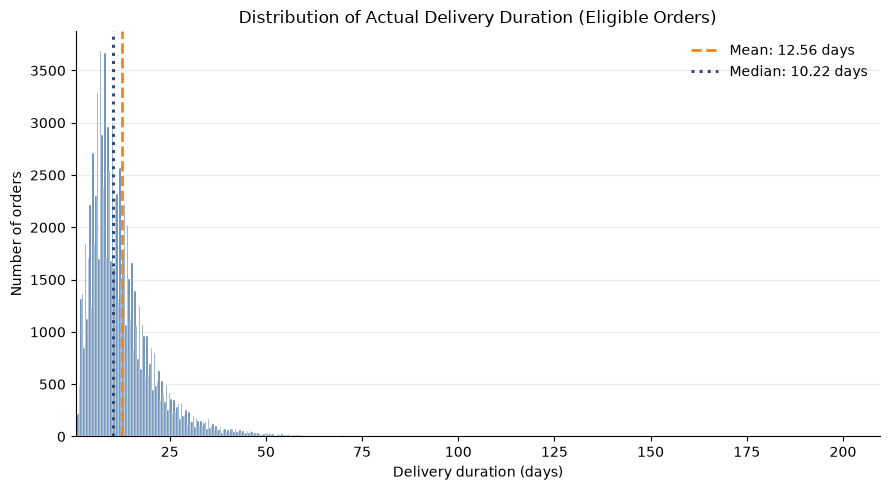

Delivery duration has skewness **3.83**, so it is **right-skewed**. The middle 50% lies between 6.77 and 15.72 days. The mean (12.56) is above the median (10.22), showing how unusually long durations influence the average. For future regression evaluation, MAE will describe typical absolute error while RMSE will place greater weight on large errors in this tail.

In [11]:
histogram_edges = np.histogram_bin_edges(eligible_delivery_days, bins="fd")
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    eligible_delivery_days,
    bins=histogram_edges,
    color="#4C78A8",
    edgecolor="white",
    linewidth=0.35,
)
ax.axvline(delivery_mean, color="#F58518", linestyle="--", linewidth=2, label=f"Mean: {delivery_mean:.2f} days")
ax.axvline(delivery_median, color="#2F4B7C", linestyle=":", linewidth=2.2, label=f"Median: {delivery_median:.2f} days")
ax.set_title("Distribution of Actual Delivery Duration (Eligible Orders)")
ax.set_xlabel("Delivery duration (days)")
ax.set_ylabel("Number of orders")
ax.set_xlim(delivery_min, delivery_max)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

skew_direction = "right-skewed" if delivery_skewness > 0 else ("left-skewed" if delivery_skewness < 0 else "approximately symmetric by skewness")
display(Markdown(
    f"Delivery duration has skewness **{delivery_skewness:.2f}**, so it is **{skew_direction}**. "
    f"The middle 50% lies between {q1:.2f} and {q3:.2f} days. The mean "
    f"({delivery_mean:.2f}) is {'above' if delivery_mean > delivery_median else 'below'} the median "
    f"({delivery_median:.2f}), showing how unusually long durations influence the average. "
    "For future regression evaluation, MAE will describe typical absolute error while RMSE will place greater weight on large errors in this tail."
))

### 2.5 Regression — Spread and Potential Outliers

The horizontal box plot and IQR fences describe statistical extremeness only. All eligible observations remain in the analysis; no value is removed, capped, transformed, or treated as a data-quality error without supporting evidence.

Metric,Value
Q1,6.77 days
Q3,15.72 days
IQR,8.95 days
Lower fence,-6.66 days
Upper fence,29.15 days
Below lower fence,0 (0.00%)
Above upper fence,"4,896 (5.08%)"


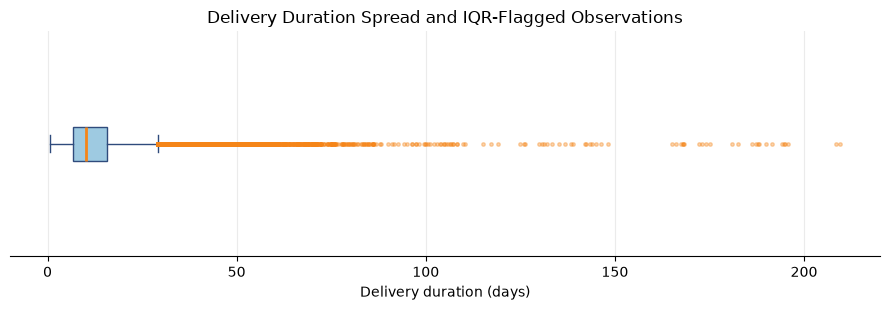

The middle 50% spans **8.95 days**. The conventional upper fence is **29.15 days**; **4,896 (5.08%)** of eligible durations exceed it. The lower fence is -6.66 days, with 0 (0.00%) below it. These are potential statistical outliers, not automatically invalid orders.

In [12]:
lower_fence = q1 - 1.5 * delivery_iqr
upper_fence = q3 + 1.5 * delivery_iqr
below_lower_fence = eligible_delivery_days.lt(lower_fence)
above_upper_fence = eligible_delivery_days.gt(upper_fence)
lower_outlier_count = int(below_lower_fence.sum())
upper_outlier_count = int(above_upper_fence.sum())
lower_outlier_percentage = lower_outlier_count / regression_eligible_count * 100
upper_outlier_percentage = upper_outlier_count / regression_eligible_count * 100

iqr_summary = pd.DataFrame(
    {
        "Metric": [
            "Q1", "Q3", "IQR", "Lower fence", "Upper fence",
            "Below lower fence", "Above upper fence",
        ],
        "Value": [
            f"{q1:.2f} days", f"{q3:.2f} days", f"{delivery_iqr:.2f} days",
            f"{lower_fence:.2f} days", f"{upper_fence:.2f} days",
            f"{lower_outlier_count:,} ({lower_outlier_percentage:.2f}%)",
            f"{upper_outlier_count:,} ({upper_outlier_percentage:.2f}%)",
        ],
    }
)
display(iqr_summary.style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.boxplot(
    eligible_delivery_days,
    orientation="horizontal",
    patch_artist=True,
    boxprops={"facecolor": "#9ECAE1", "edgecolor": "#2F4B7C"},
    medianprops={"color": "#F58518", "linewidth": 2},
    whiskerprops={"color": "#2F4B7C"},
    capprops={"color": "#2F4B7C"},
    flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": "#F58518", "markeredgecolor": "#F58518", "alpha": 0.35},
)
ax.set_title("Delivery Duration Spread and IQR-Flagged Observations")
ax.set_xlabel("Delivery duration (days)")
ax.set_yticks([])
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

display(Markdown(
    f"The middle 50% spans **{delivery_iqr:.2f} days**. The conventional upper fence is "
    f"**{upper_fence:.2f} days**; **{upper_outlier_count:,} ({upper_outlier_percentage:.2f}%)** "
    f"of eligible durations exceed it. The lower fence is {lower_fence:.2f} days, with "
    f"{lower_outlier_count:,} ({lower_outlier_percentage:.2f}%) below it. "
    "These are potential statistical outliers, not automatically invalid orders."
))

### 2.6 Regression — Percentiles and ECDF

An ECDF shows the share of eligible orders whose actual delivery duration is less than or equal to each X-axis value. Percentile guides summarize cumulative actual duration, not whether delivery met its promised date.

Percentile,Delivery duration (days)
P50,10.22
P75,15.72
P90,23.10
P95,29.27
P99,46.05


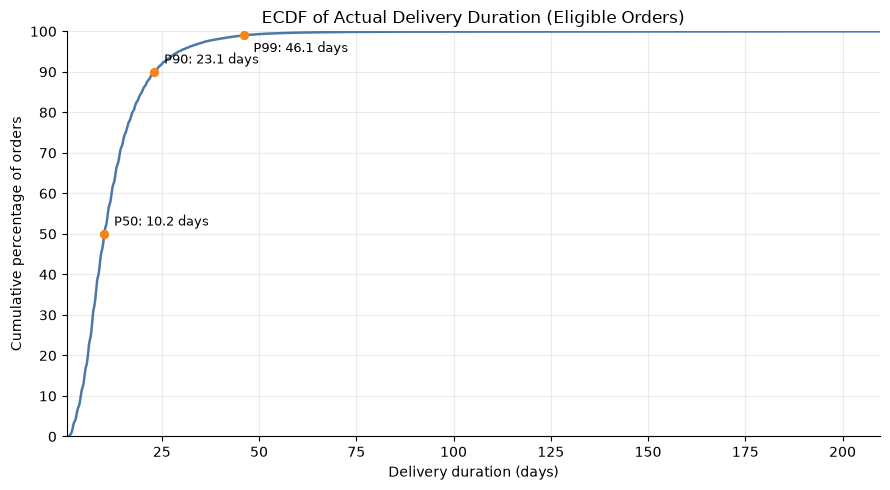

For example, the observed **P90 of 23.10 days** means approximately 90% of eligible orders were delivered within that actual elapsed duration. P95 is 29.27 days and P99 is 46.05 days. Ties can make the empirical proportion at a percentile threshold differ slightly from its nominal percentage.

In [13]:
ecdf_x = np.sort(eligible_delivery_days.to_numpy())
ecdf_y = np.arange(1, regression_eligible_count + 1) / regression_eligible_count * 100
percentile_levels = [0.50, 0.75, 0.90, 0.95, 0.99]
percentile_summary = pd.DataFrame(
    {
        "Percentile": [f"P{int(level * 100)}" for level in percentile_levels],
        "Delivery duration (days)": [delivery_quantiles.loc[level] for level in percentile_levels],
    }
)
display(percentile_summary.style.format({"Delivery duration (days)": "{:.2f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ecdf_x, ecdf_y, color="#4C78A8", linewidth=1.8)
for level in [0.50, 0.90, 0.99]:
    value = delivery_quantiles.loc[level]
    percentage = level * 100
    ax.scatter(value, percentage, color="#F58518", s=32, zorder=3)
    ax.annotate(
        f"P{int(percentage)}: {value:.1f} days",
        (value, percentage),
        xytext=(7, -12 if level == 0.99 else 6),
        textcoords="offset points",
        fontsize=9,
    )
ax.set_title("ECDF of Actual Delivery Duration (Eligible Orders)")
ax.set_xlabel("Delivery duration (days)")
ax.set_ylabel("Cumulative percentage of orders")
ax.set_xlim(delivery_min, delivery_max)
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 10))
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

display(Markdown(
    f"For example, the observed **P90 of {delivery_quantiles.loc[0.90]:.2f} days** means "
    "approximately 90% of eligible orders were delivered within that actual elapsed duration. "
    f"P95 is {delivery_quantiles.loc[0.95]:.2f} days and P99 is {delivery_quantiles.loc[0.99]:.2f} days. "
    "Ties can make the empirical proportion at a percentile threshold differ slightly from its nominal percentage."
))

### 2.7 Regression — Unusually Long Deliveries

Tail groups are defined with a strict `>` comparison to the observed P90, P95, and P99 thresholds. Tied durations at a threshold remain outside that tail group, so observed percentages need not equal exactly 10%, 5%, or 1%.

In [14]:
tail_rows = []
for level in [0.90, 0.95, 0.99]:
    threshold = delivery_quantiles.loc[level]
    tail_values = eligible_delivery_days[eligible_delivery_days.gt(threshold)]
    tail_rows.append(
        {
            "Tail group": f"> P{int(level * 100)}",
            "Threshold (days)": threshold,
            "Orders": len(tail_values),
            "Eligible orders (%)": len(tail_values) / regression_eligible_count * 100,
            "Tail minimum (days)": tail_values.min(),
            "Tail median (days)": tail_values.median(),
            "Tail maximum (days)": tail_values.max(),
            "Tail median minus overall median (days)": tail_values.median() - delivery_median,
        }
    )
tail_summary = pd.DataFrame(tail_rows)
display(
    tail_summary.style.format(
        {
            "Threshold (days)": "{:.2f}",
            "Orders": "{:,}",
            "Eligible orders (%)": "{:.2f}%",
            "Tail minimum (days)": "{:.2f}",
            "Tail median (days)": "{:.2f}",
            "Tail maximum (days)": "{:.2f}",
            "Tail median minus overall median (days)": "{:.2f}",
        }
    ).hide(axis="index")
)

p95_tail = tail_summary.loc[tail_summary["Tail group"].eq("> P95")].iloc[0]
display(Markdown(
    f"Using the strict threshold definition, **{int(p95_tail['Orders']):,} "
    f"({p95_tail['Eligible orders (%)']:.2f}%)** orders exceed P95 "
    f"({p95_tail['Threshold (days)']:.2f} days). Their median duration is "
    f"**{p95_tail['Tail median (days)']:.2f} days**, which is "
    f"**{p95_tail['Tail median minus overall median (days)']:.2f} days longer** than the overall median. "
    "A separate tail histogram is omitted because the full-range histogram, box plot, ECDF, and exact tail table already provide complementary views without duplicating the same distribution."
))

Tail group,Threshold (days),Orders,Eligible orders (%),Tail minimum (days),Tail median (days),Tail maximum (days),Tail median minus overall median (days)
> P90,23.10,"9,647",10.00%,23.10,29.27,209.63,19.06
> P95,29.27,"4,824",5.00%,29.27,36.31,209.63,26.10
> P99,46.05,965,1.00%,46.05,54.06,209.63,43.84


Using the strict threshold definition, **4,824 (5.00%)** orders exceed P95 (29.27 days). Their median duration is **36.31 days**, which is **26.10 days longer** than the overall median. A separate tail histogram is omitted because the full-range histogram, box plot, ECDF, and exact tail table already provide complementary views without duplicating the same distribution.

### 2.8 Consolidated Findings and Learning Questions

The summary below is generated from the preceding calculations. It remains descriptive and does not select algorithms, transformations, thresholds, or preprocessing decisions.

In [15]:
display(Markdown(f"""
#### Classification findings

- **Eligible population:** {classification_eligible_count:,} orders under the existing Task 1.1 mask.
- **On time:** {on_time_count:,} ({class_percentages.loc[0]:.2f}%); **late:** {late_count:,} ({class_percentages.loc[1]:.2f}%).
- **Majority/minority ratio:** {majority_minority_ratio:.2f}:1; an always-majority rule would achieve {majority_baseline_accuracy:.2f}% accuracy while finding no late orders.
- **Evaluation implication:** accuracy alone is misleading for this imbalance. Later classification evaluation should include precision, recall, F1-score, and PR-AUC.

#### Regression findings

- **Eligible population:** {regression_eligible_count:,} orders under the existing Task 1.1 mask.
- **Center and spread:** mean {delivery_mean:.2f} days, median {delivery_median:.2f} days, standard deviation {delivery_std:.2f} days, and IQR {delivery_iqr:.2f} days.
- **Upper percentiles:** P90 {delivery_quantiles.loc[0.90]:.2f}, P95 {delivery_quantiles.loc[0.95]:.2f}, and P99 {delivery_quantiles.loc[0.99]:.2f} days.
- **Shape:** skewness is {delivery_skewness:.2f}; the maximum is {delivery_max:.2f} days compared with a minimum of {delivery_min:.2f} days.
- **Unusually long deliveries:** {upper_outlier_count:,} ({upper_outlier_percentage:.2f}%) exceed the IQR upper fence of {upper_fence:.2f} days. The strict >P95 group contains {int(p95_tail['Orders']):,} orders and has a median duration of {p95_tail['Tail median (days)']:.2f} days. These observations are retained as valid unless separate evidence proves otherwise.

#### Future ML implications

Classification metrics must expose performance on the late minority rather than reward majority predictions. For regression, MAE weights each absolute error linearly, whereas RMSE squares errors and will react more strongly to unusually long-delivery mistakes. Understanding both target distributions is therefore necessary before choosing evaluation strategies, but it does not itself justify target transformation or outlier removal.

**Governance limitation:** the six timestamp-complete non-delivered orders remain excluded by the unchanged provisional Task 1.1 masks. Resolving that cohort rule requires an explicit project-governance decision, not a Task 2 EDA change.
"""))


#### Classification findings

- **Eligible population:** 96,470 orders under the existing Task 1.1 mask.
- **On time:** 88,644 (91.89%); **late:** 7,826 (8.11%).
- **Majority/minority ratio:** 11.33:1; an always-majority rule would achieve 91.89% accuracy while finding no late orders.
- **Evaluation implication:** accuracy alone is misleading for this imbalance. Later classification evaluation should include precision, recall, F1-score, and PR-AUC.

#### Regression findings

- **Eligible population:** 96,470 orders under the existing Task 1.1 mask.
- **Center and spread:** mean 12.56 days, median 10.22 days, standard deviation 9.55 days, and IQR 8.95 days.
- **Upper percentiles:** P90 23.10, P95 29.27, and P99 46.05 days.
- **Shape:** skewness is 3.83; the maximum is 209.63 days compared with a minimum of 0.53 days.
- **Unusually long deliveries:** 4,896 (5.08%) exceed the IQR upper fence of 29.15 days. The strict >P95 group contains 4,824 orders and has a median duration of 36.31 days. These observations are retained as valid unless separate evidence proves otherwise.

#### Future ML implications

Classification metrics must expose performance on the late minority rather than reward majority predictions. For regression, MAE weights each absolute error linearly, whereas RMSE squares errors and will react more strongly to unusually long-delivery mistakes. Understanding both target distributions is therefore necessary before choosing evaluation strategies, but it does not itself justify target transformation or outlier removal.

**Governance limitation:** the six timestamp-complete non-delivered orders remain excluded by the unchanged provisional Task 1.1 masks. Resolving that cohort rule requires an explicit project-governance decision, not a Task 2 EDA change.


#### Learning Questions

These questions are intentionally unanswered.

1. What is the difference between class distribution and class imbalance?
2. Why can a majority-class-only model achieve high accuracy without detecting late deliveries?
3. What is the difference between mean and median?
4. Why is the median less sensitive to extreme delivery durations?
5. What does standard deviation measure?
6. What is the difference between standard deviation and IQR?
7. What do P90, P95, and P99 mean?
8. What is skewness, and how do we interpret positive and negative values?
9. Why are box-plot outliers not necessarily data errors?
10. What is an ECDF, and how is it different from a histogram?
11. Why might RMSE be more sensitive than MAE to unusually long deliveries?
12. Why should we understand target distributions before model development?